# Problema 2 — Class Imbalance (Desbalanceo de clases)
## Dataset: Base 2 — Matrícula y secciones 2023

**Qué vamos a aprender:**
1. Cómo accuracy miente cuando hay desbalanceo
2. Por qué F1-macro, AUC-PR y MCC son métricas más honestas
3. Cómo mitigarlo con `class_weight`, SMOTE y ajuste de threshold

### ¿Qué es class imbalance?
Una o más clases tienen muchas menos muestras que otras.
El modelo aprende a predecir la mayoría y obtiene **alta accuracy con recall cercano a 0**
en la clase minoritaria.

### Escenario educativo
Vamos a **construir un desbalance artificial**: identificar escuelas con tasa de repitencia extrema (>20%),
que son una clase rara (~3-5% del total) y de alto interés social (indicador crítico).

## 0. Setup y carga

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, matthews_corrcoef,
    precision_recall_curve, average_precision_score, roc_auc_score
)

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)

ARCHIVO = 'data/matricula_secciones_2023.csv'
df_raw = pd.read_csv(ARCHIVO, sep=';', encoding='utf-8-sig', low_memory=False)

mat_cols = [c for c in ['_1','_2','_3','_4','_5','_6','_7','_8','_9','_10','_11','_12','_1314','_snu'] if c in df_raw.columns]
rep_cols = [c for c in ['r_1','r_2','r_3','r_4','r_5','r_6','r_7','r_8','r_9','r_10','r_11','r_12','r_1314','r_20'] if c in df_raw.columns]
sec_cols = [c for c in ['_sec1','_sec2','_sec3','_sec4','_sec5','_sec6','_sec7','_sec8','_sec9','_sec10','_sec11','_sec12','_sec1314','_sec20'] if c in df_raw.columns]

df = df_raw.copy()
df['matricula_total']   = df[mat_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['repetidores_total'] = df[rep_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['secciones_total']   = df[sec_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)

df = df[(df['matricula_total'] > 0) & df['repetidores_total'].notna()].copy()
df['tasa_repitencia'] = df['repetidores_total'] / df['matricula_total']

# Target BINARIO desbalanceado: escuelas con repitencia extrema (>15%)
UMBRAL = 0.15
df['repitencia_extrema'] = (df['tasa_repitencia'] > UMBRAL).astype(int)

print(f'Escuelas total: {len(df):,}')
print(f'Umbral de "repitencia extrema": {UMBRAL*100:.0f}%')
print(f'\nDistribución del target:')
counts = df['repitencia_extrema'].value_counts().sort_index()
print(f'  Clase 0 (normal):  {counts[0]:,} ({100*counts[0]/len(df):.1f}%)')
print(f'  Clase 1 (extrema): {counts[1]:,} ({100*counts[1]/len(df):.1f}%)')
print(f'\nRatio de desbalanceo: 1 caso extremo por cada {counts[0]/counts[1]:.1f} normales')

Escuelas total: 35,169
Umbral de "repitencia extrema": 15%

Distribución del target:
  Clase 0 (normal):  32,646 (92.8%)
  Clase 1 (extrema): 2,523 (7.2%)

Ratio de desbalanceo: 1 caso extremo por cada 12.9 normales


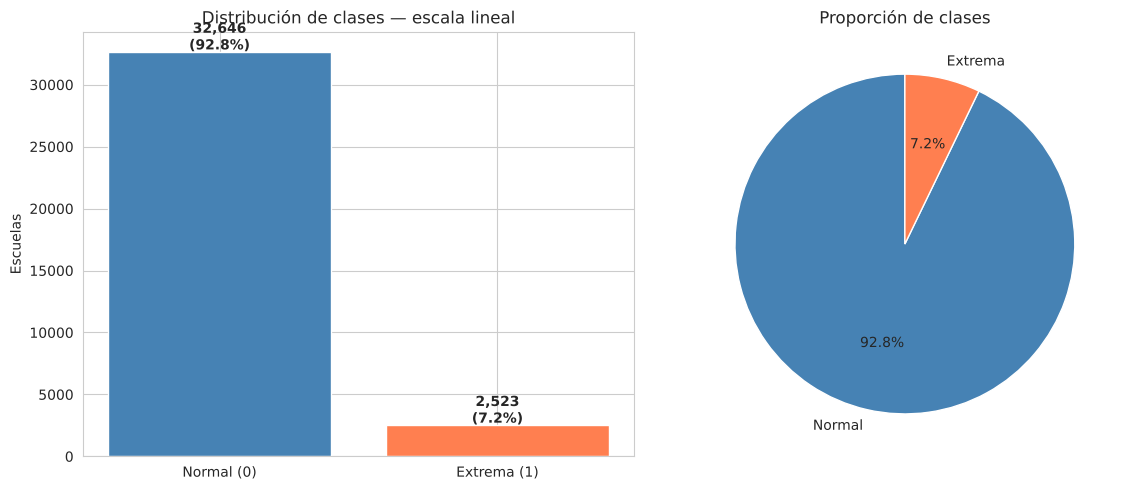

In [2]:
# Visualizar el desbalance
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Normal (0)', 'Extrema (1)'], counts.values, color=['steelblue', 'coral'], edgecolor='white')
axes[0].set_title('Distribución de clases — escala lineal')
axes[0].set_ylabel('Escuelas')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 200, f'{v:,}\n({100*v/len(df):.1f}%)', ha='center', fontweight='bold')

axes[1].pie(counts.values, labels=['Normal', 'Extrema'], autopct='%1.1f%%',
            colors=['steelblue', 'coral'], startangle=90)
axes[1].set_title('Proporción de clases')

plt.tight_layout()
plt.show()

## 1. El problema: accuracy miente

Entrenamos un modelo SIN ninguna corrección y observamos lo que pasa con la métrica más popular.

In [3]:
FEATURES = ['matricula_total', 'secciones_total', 'provincia', 'sector', 'ambito']
num_cols = ['matricula_total', 'secciones_total']
cat_cols = ['provincia', 'sector', 'ambito']

X = df[FEATURES].copy()
y = df['repitencia_extrema'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])

# Modelo SIN corrección
pipe = Pipeline([('pre', pre), ('model', LogisticRegression(max_iter=1000, random_state=42))])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

print('=== Modelo SIN corrección ===')
print(f'  Accuracy:         {accuracy_score(y_test, y_pred):.4f}  ← ¡mirá qué alta!')
print(f'  Precision clase1: {precision_score(y_test, y_pred, zero_division=0):.4f}')
print(f'  Recall clase1:    {recall_score(y_test, y_pred, zero_division=0):.4f}  ← pero mirá esto')
print(f'  F1 clase1:        {f1_score(y_test, y_pred, zero_division=0):.4f}')
print(f'  F1 macro:         {f1_score(y_test, y_pred, average="macro"):.4f}')
print(f'  MCC:              {matthews_corrcoef(y_test, y_pred):.4f}')
print(f'  AUC-ROC:          {roc_auc_score(y_test, y_proba):.4f}')
print(f'  AUC-PR:           {average_precision_score(y_test, y_proba):.4f}')
print()
print('🚨 Accuracy parece buena, pero el Recall de la clase 1 es catastrófico.')
print('   El modelo básicamente NO detecta los casos extremos.')

=== Modelo SIN corrección ===
  Accuracy:         0.9282  ← ¡mirá qué alta!
  Precision clase1: 0.0000
  Recall clase1:    0.0000  ← pero mirá esto
  F1 clase1:        0.0000
  F1 macro:         0.4814
  MCC:              0.0000
  AUC-ROC:          0.6983
  AUC-PR:           0.1464

🚨 Accuracy parece buena, pero el Recall de la clase 1 es catastrófico.
   El modelo básicamente NO detecta los casos extremos.


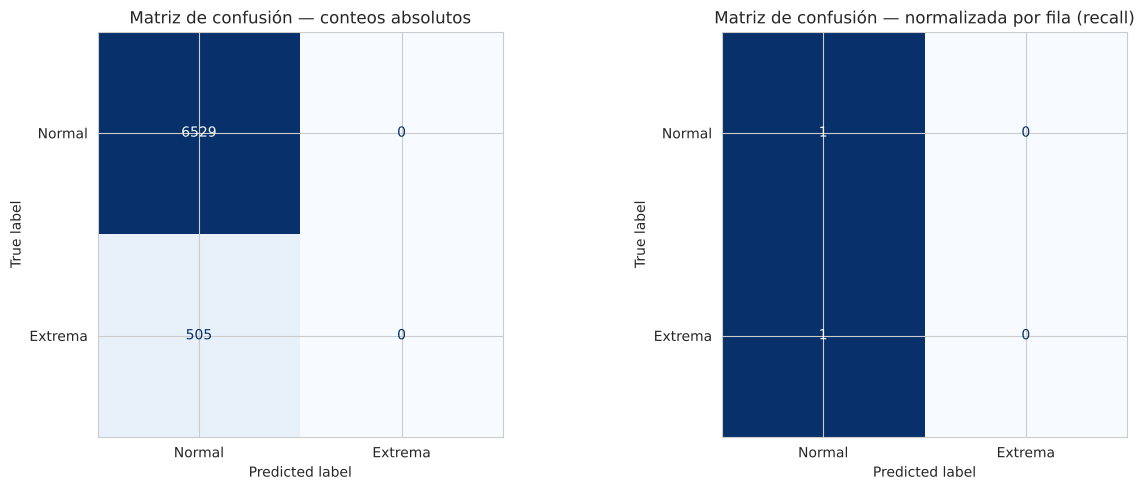


🔍 Diagnóstico detallado:
  Casos reales de clase 1 en test: 505
  Casos correctamente detectados (TP): 0
  Casos perdidos (FN):                 505
  → Recall = 0/505 = 0.0000

Si este modelo se desplegara para asignar recursos a escuelas en riesgo,
habríamos IGNORADO 505 escuelas que realmente necesitan apoyo.


In [4]:
# Matriz de confusión — acá se ve el problema
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Extrema']).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Matriz de confusión — conteos absolutos')

cm_norm = cm / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(cm_norm.round(3), display_labels=['Normal', 'Extrema']).plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Matriz de confusión — normalizada por fila (recall)')

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\n🔍 Diagnóstico detallado:')
print(f'  Casos reales de clase 1 en test: {tp + fn}')
print(f'  Casos correctamente detectados (TP): {tp}')
print(f'  Casos perdidos (FN):                 {fn}')
print(f'  → Recall = {tp}/{tp+fn} = {tp/(tp+fn):.4f}')
print()
print('Si este modelo se desplegara para asignar recursos a escuelas en riesgo,')
print(f'habríamos IGNORADO {fn} escuelas que realmente necesitan apoyo.')

## 2. ¿Por qué accuracy miente?

Considerá un modelo **trivial** que siempre predice la clase mayoritaria (0 = normal).

In [5]:
# Modelo trivial: predecir siempre 0
y_pred_trivial = np.zeros_like(y_test)

print('=== Modelo TRIVIAL (siempre predice "Normal") ===')
print(f'  Accuracy:       {accuracy_score(y_test, y_pred_trivial):.4f}  ← altísima')
print(f'  Recall clase 1: {recall_score(y_test, y_pred_trivial, zero_division=0):.4f}  ← CERO')
print(f'  F1 macro:       {f1_score(y_test, y_pred_trivial, average="macro", zero_division=0):.4f}  ← delata el truco')
print(f'  MCC:            {matthews_corrcoef(y_test, y_pred_trivial):.4f}  ← también')
print()
print('💡 Lección: un modelo INÚTIL tiene accuracy alta. Por eso accuracy es engañosa con desbalanceo.')
print('   F1 macro y MCC no se dejan engañar.')

=== Modelo TRIVIAL (siempre predice "Normal") ===
  Accuracy:       0.9282  ← altísima
  Recall clase 1: 0.0000  ← CERO
  F1 macro:       0.4814  ← delata el truco
  MCC:            0.0000  ← también

💡 Lección: un modelo INÚTIL tiene accuracy alta. Por eso accuracy es engañosa con desbalanceo.
   F1 macro y MCC no se dejan engañar.


## 3. Solución 1 — class_weight='balanced'

Ajusta la función de pérdida para que los errores en la clase minoritaria pesen más.

In [6]:
pipe_weighted = Pipeline([
    ('pre', pre),
    ('model', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])
pipe_weighted.fit(X_train, y_train)
y_pred_w  = pipe_weighted.predict(X_test)
y_proba_w = pipe_weighted.predict_proba(X_test)[:, 1]

print('=== CON class_weight="balanced" ===')
print(f'  Accuracy:         {accuracy_score(y_test, y_pred_w):.4f}  ← bajó')
print(f'  Precision clase1: {precision_score(y_test, y_pred_w, zero_division=0):.4f}')
print(f'  Recall clase1:    {recall_score(y_test, y_pred_w, zero_division=0):.4f}  ← subió muchísimo')
print(f'  F1 macro:         {f1_score(y_test, y_pred_w, average="macro"):.4f}')
print(f'  MCC:              {matthews_corrcoef(y_test, y_pred_w):.4f}')
print(f'  AUC-PR:           {average_precision_score(y_test, y_proba_w):.4f}')
print()
print('✅ Menos accuracy, pero MUCHO mejor recall en la clase minoritaria.')
print('   En un contexto real (detectar escuelas en riesgo), esto es lo que importa.')

=== CON class_weight="balanced" ===
  Accuracy:         0.5756  ← bajó
  Precision clase1: 0.1132
  Recall clase1:    0.7188  ← subió muchísimo
  F1 macro:         0.4537
  MCC:              0.1469
  AUC-PR:           0.1421

✅ Menos accuracy, pero MUCHO mejor recall en la clase minoritaria.
   En un contexto real (detectar escuelas en riesgo), esto es lo que importa.


## 4. Solución 2 — ajuste del threshold de decisión

Por defecto sklearn usa 0.5 como threshold. Podemos bajarlo para aumentar recall.

In [7]:
thresholds = [0.5, 0.3, 0.2, 0.1]

tabla = []
for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    tabla.append({
        'threshold': t,
        'accuracy':  accuracy_score(y_test, y_pred_t),
        'precision': precision_score(y_test, y_pred_t, zero_division=0),
        'recall':    recall_score(y_test, y_pred_t, zero_division=0),
        'f1_macro':  f1_score(y_test, y_pred_t, average='macro'),
        'mcc':       matthews_corrcoef(y_test, y_pred_t)
    })

tabla_df = pd.DataFrame(tabla).round(4)
print('Efecto de bajar el threshold de decisión:')
print(tabla_df.to_string(index=False))
print()
print('Observación: bajar el threshold sube recall pero baja precision.')
print('El valor correcto depende del costo relativo de FP vs FN en el problema.')

Efecto de bajar el threshold de decisión:
 threshold  accuracy  precision  recall  f1_macro    mcc
       0.5    0.9282     0.0000  0.0000    0.4814 0.0000
       0.3    0.9283     0.6667  0.0040    0.4854 0.0476
       0.2    0.9154     0.2500  0.0891    0.5435 0.1119
       0.1    0.7337     0.1330  0.4911    0.5246 0.1425

Observación: bajar el threshold sube recall pero baja precision.
El valor correcto depende del costo relativo de FP vs FN en el problema.


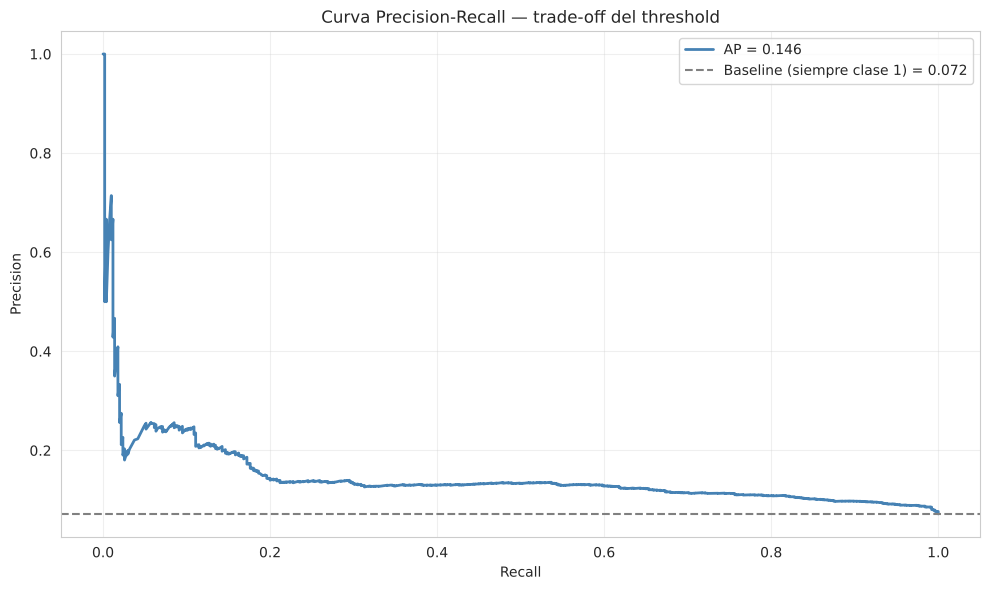


La curva muestra el trade-off completo:
  - Moverse a la derecha (más recall) requiere bajar precision
  - El baseline es la proporción de clase positiva en test
  - Cualquier modelo razonable debe estar POR ENCIMA del baseline


In [8]:
# Curva Precision-Recall
prec, rec, thr = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(rec, prec, color='steelblue', linewidth=2, label=f'AP = {ap:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall — trade-off del threshold')
plt.axhline(y_test.mean(), color='gray', linestyle='--', label=f'Baseline (siempre clase 1) = {y_test.mean():.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nLa curva muestra el trade-off completo:')
print('  - Moverse a la derecha (más recall) requiere bajar precision')
print('  - El baseline es la proporción de clase positiva en test')
print('  - Cualquier modelo razonable debe estar POR ENCIMA del baseline')

## 5. Solución 3 — SMOTE (sobremuestreo sintético)

Genera ejemplos sintéticos de la clase minoritaria interpolando entre sus vecinos.

> ⚠️ **SMOTE debe aplicarse SOLO al conjunto de training, nunca al test.**
> Y siempre dentro del pipeline, no antes del split.

In [9]:
# SMOTE requiere la librería imbalanced-learn
# !pip install imbalanced-learn

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

    pipe_smote = ImbPipeline([
        ('pre', pre),
        ('smote', SMOTE(random_state=42)),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ])
    pipe_smote.fit(X_train, y_train)
    y_pred_s  = pipe_smote.predict(X_test)
    y_proba_s = pipe_smote.predict_proba(X_test)[:, 1]

    print('=== CON SMOTE (dentro del pipeline) ===')
    print(f'  Accuracy:         {accuracy_score(y_test, y_pred_s):.4f}')
    print(f'  Precision clase1: {precision_score(y_test, y_pred_s, zero_division=0):.4f}')
    print(f'  Recall clase1:    {recall_score(y_test, y_pred_s, zero_division=0):.4f}')
    print(f'  F1 macro:         {f1_score(y_test, y_pred_s, average="macro"):.4f}')
    print(f'  MCC:              {matthews_corrcoef(y_test, y_pred_s):.4f}')
    print(f'  AUC-PR:           {average_precision_score(y_test, y_proba_s):.4f}')
except ImportError:
    print('imbalanced-learn no instalada. Instalá con: pip install imbalanced-learn')
    print('Y volvé a correr esta celda.')

imbalanced-learn no instalada. Instalá con: pip install imbalanced-learn
Y volvé a correr esta celda.


## 6. Comparación final de las 3 estrategias

Comparación de estrategias:
                       accuracy  recall_c1  f1_macro     mcc
modelo                                                      
Sin corrección           0.9282     0.0000    0.4814  0.0000
class_weight balanced    0.5756     0.7188    0.4537  0.1469


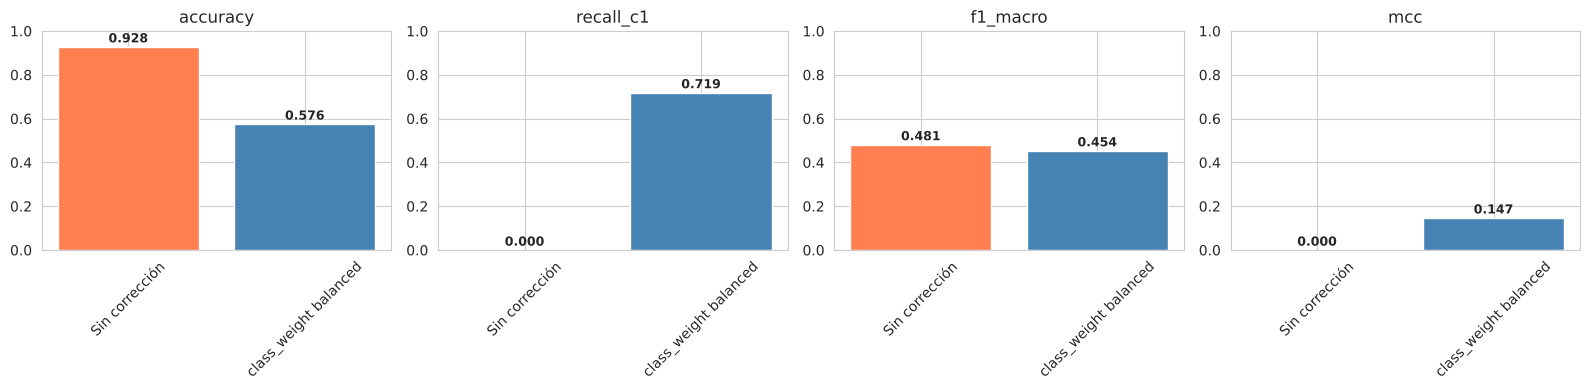

In [10]:
resultados = [
    {'modelo': 'Sin corrección',        'accuracy': accuracy_score(y_test, y_pred),    'recall_c1': recall_score(y_test, y_pred, zero_division=0),    'f1_macro': f1_score(y_test, y_pred, average='macro'),    'mcc': matthews_corrcoef(y_test, y_pred)},
    {'modelo': 'class_weight balanced', 'accuracy': accuracy_score(y_test, y_pred_w),  'recall_c1': recall_score(y_test, y_pred_w, zero_division=0),  'f1_macro': f1_score(y_test, y_pred_w, average='macro'),  'mcc': matthews_corrcoef(y_test, y_pred_w)},
]

try:
    resultados.append({'modelo': 'SMOTE', 'accuracy': accuracy_score(y_test, y_pred_s), 'recall_c1': recall_score(y_test, y_pred_s, zero_division=0), 'f1_macro': f1_score(y_test, y_pred_s, average='macro'), 'mcc': matthews_corrcoef(y_test, y_pred_s)})
except NameError:
    pass

comp = pd.DataFrame(resultados).set_index('modelo').round(4)
print('Comparación de estrategias:')
print(comp.to_string())

# Visualización
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['accuracy', 'recall_c1', 'f1_macro', 'mcc']):
    bars = ax.bar(comp.index, comp[col],
                  color=['coral', 'steelblue', 'seagreen'][:len(comp)])
    ax.set_title(col)
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=45)
    for bar, v in zip(bars, comp[col]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Resumen — dónde está el problema y por qué

### Dónde aparece el class imbalance
- En el **target** del dataset: una clase con << 10% del total
- Común en: fraude, enfermedades raras, fallas industriales, eventos adversos
- En nuestro caso: escuelas con repitencia >15% son una minoría crítica

### Por qué es un problema
1. **La loss function** se domina por la clase mayoritaria
2. **Los gradientes** de la minoría son sobrepasados en cada batch
3. **La decisión óptima bayesiana** tiende a predecir siempre la mayoría
4. **La accuracy** reporta valores altísimos aunque el modelo sea inútil

### Cómo detectarlo
- Distribución del target: ¿alguna clase < 10%?
- Recall de la clase minoritaria ≈ 0
- F1-macro muy bajo a pesar de accuracy alta
- MCC cercano a 0

### Cómo resolverlo
| Estrategia | Ventaja | Desventaja |
|---|---|---|
| `class_weight='balanced'` | Sin modificar datos, robusto | No siempre alcanza si el desbalance es extremo |
| Ajuste de threshold | Control directo del trade-off | No mejora el modelo, solo ajusta decisiones |
| SMOTE / Oversampling | Aumenta datos para la minoría | Puede generar datos sintéticos poco realistas |
| Undersampling | Rápido, simple | Descarta información valiosa de la mayoría |

### Regla operativa
> **Accuracy en datos desbalanceados está PROHIBIDA.**  
> Usá F1-macro o MCC como métrica principal.  
> Para evaluar el trade-off: curva Precision-Recall y AUC-PR.